<a href="https://colab.research.google.com/github/dimi-kri/ML-Ergasia1/blob/main/Ergasia1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Εργασία 1 – Επιβλεπόμενη Μάθηση


## Βιβλιοθήκες

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, mean_squared_error, mean_absolute_error, r2_score)
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Μέρος 1 – Λογιστική Παλινδρόμηση

## Ερώτημα 1.1 – Φόρτωση και περιγραφή δεδομένων

In [24]:
df = pd.read_csv('diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


### Περιγραφή μεταβλητών

| Μεταβλητή | Περιγραφή |
|---|---|
| **Pregnancies** | Ο συνολικός αριθμός των φορών που μια ασθενής έχει μείνει έγκυος (πλήθος). |
| **Glucose** | Η συγκέντρωση γλυκόζης στο πλάσμα 2 ώρες μετά από δοκιμασία ανοχής γλυκόζης (mg/dL). |
| **BloodPressure** | Η διαστολική αρτηριακή πίεση (mm Hg). |
| **SkinThickness** | Το πάχος της πτυχής του δέρματος στο τρικέφαλο, ένδειξη λίπους κάτω από το δέρμα  (mm). |
| **Insulin** | Η ινσουλίνη στο αίμα, 2 ώρες μετά τη χορήγηση γλυκόζης (μU/ml). |
| **BMI** | Ο Δείκτης Μάζας Σώματος, βάρος (kg) / ύψος² (m²). |
| **DiabetesPedigreeFunction** | Δείκτης κληρονομικής προδιάθεσης για διαβήτη με βάση το οικογενειακό ιστορικό. |
| **Age** | Η ηλικία του ασθενούς (έτη). |
| **Outcome** | Το αποτέλεσμα: 1 αν ο ασθενής έχει διαβήτη, 0 αν δεν έχει. |

### Στατιστικά χαρακτηριστικών


In [25]:
df.describe().loc[['mean', 'std', 'min', 'max']].round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


**Σημείωση:** Σε αρκετές στήλες η ελάχιστη τιμή είναι 0, κάτι το οποίο είναι βιολογικά αδύνατο. Πρόκειται στην ουσία για ελλιπείς τιμές που έχουν καταχωρηθεί ως 0. Στον παρακάτω πίνακα φαίνεται το πλήθος:

In [26]:
cols_no_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
(df[cols_no_zero] == 0).sum().to_frame('Πλήθος μηδενικών τιμών')

,Πλήθος μηδενικών τιμών
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


Οι Insulin και SkinThickness έχουν πάρα πολλές ελλιπείς τιμές, ενώ οι Glucose, BloodPressure και BMI λίγες.

### Ιστογράμματα

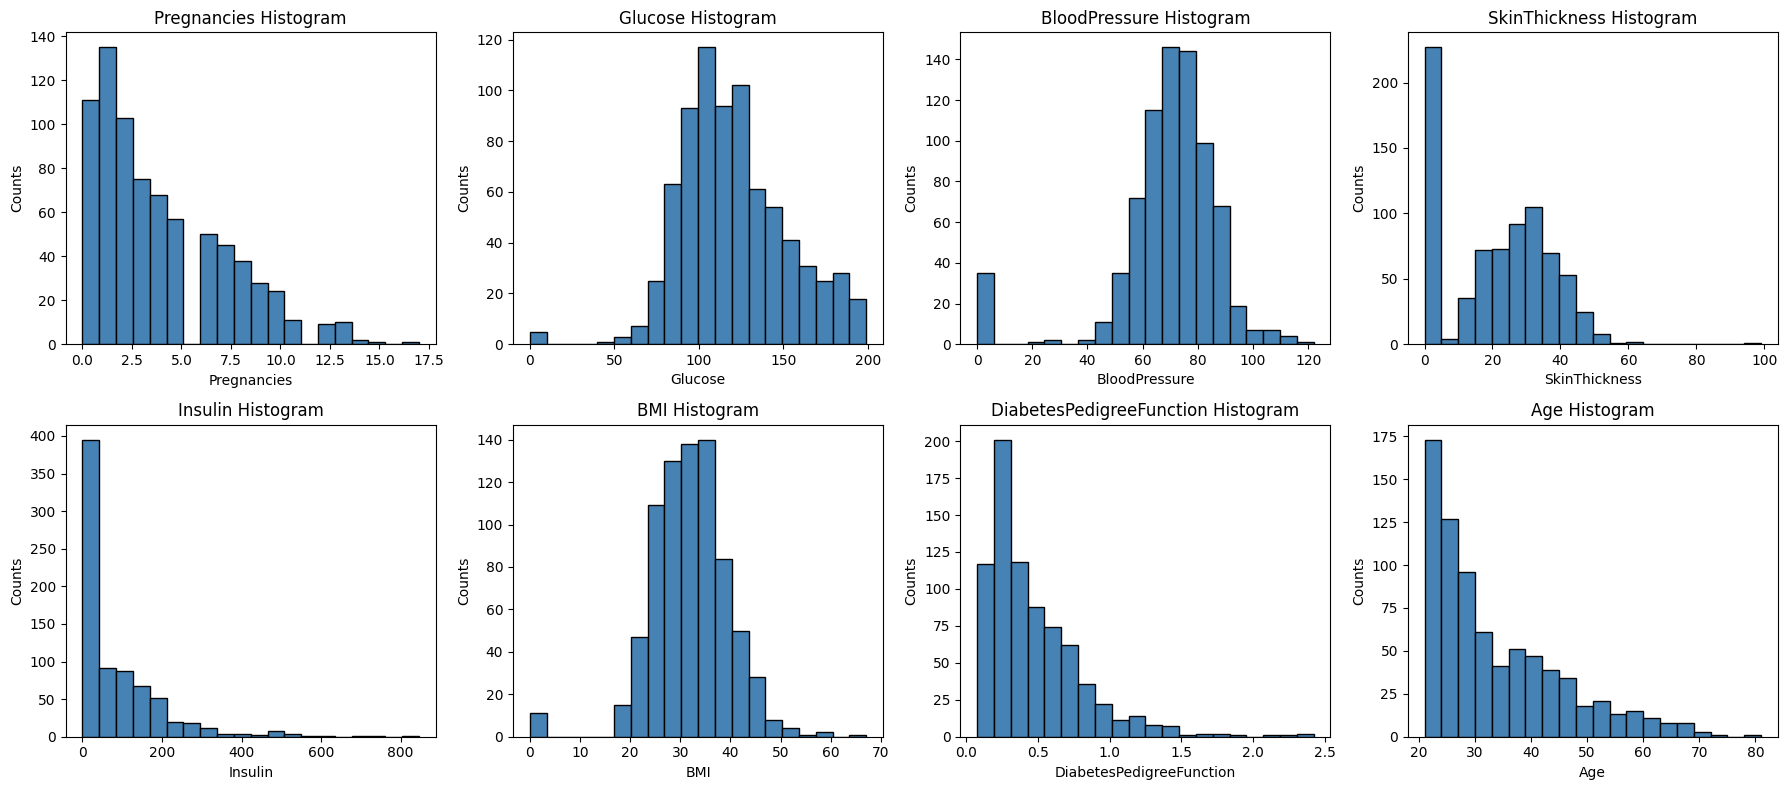

In [27]:
features = df.columns.drop('Outcome')

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), features):
    ax.hist(df[col], bins=20, edgecolor='black', color='steelblue')
    ax.set_title(f'{col} Histogram')
    ax.set_xlabel(col)
    ax.set_ylabel('Counts')
plt.tight_layout()
plt.show()

- **Glucose, BloodPressure, BMI**: περίπου κανονικές κατανομές, οι περισσότεροι ασθενείς είναι στη μέση, με μια μικρή μπάρα στο 0 που είναι οι ελλιπείς τιμές.
- **Pregnancies, Insulin, SkinThickness, DiabetesPedigreeFunction, Age**: δεξιά ασύμμετρες με πολλές μικρές τιμές και λίγες μεγάλες. Για Insulin και SkinThickness η μεγάλη μπάρα στο 0 οφείλεται στις ελλιπείς τιμές.
- Οι ασθενείς είναι κυρίως νέοι (21–40 ετών).

### Ραβδόγραμμα Outcome

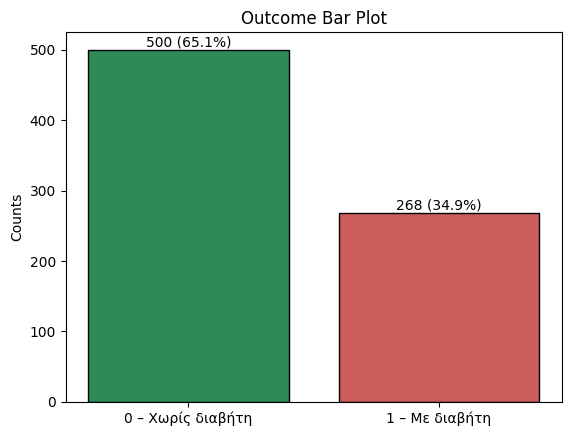

In [28]:
counts = df['Outcome'].value_counts().sort_index()

plt.bar(['0 – Χωρίς διαβήτη', '1 – Με διαβήτη'], counts.values,
        color=['seagreen', 'indianred'], edgecolor='black')
for i, v in enumerate(counts.values):
    plt.text(i, v + 5, f'{v} ({v/len(df):.1%})', ha='center')
plt.title('Outcome Bar Plot')
plt.ylabel('Counts')
plt.show()

Το σύνολο είναι **μη ισορροπημένο**: ~65% υγιείς και ~35% διαβητικοί.

## Ερώτημα 1.2 – Numpy arrays και διαχωρισμός Train-Validation


In [29]:
input_df = df.drop(columns=['Outcome'])
targets_df = df['Outcome']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape

((768, 8), (768,))

In [30]:
seed = 0
test_size = 0.3

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)

print(f'train (70%): {x_train.shape[0]}')
print(f'validation (30%): {x_test.shape[0]}')

train (70%): 537
validation (30%): 231


## Ερώτημα 1.3 – Εκπαίδευση και ακρίβεια Logistic Regression

In [31]:
model = LogisticRegression(max_iter=5000, random_state=seed)
model.fit(x_train, y_train)

LogisticRegression(max_iter=5000, random_state=0)

In [32]:
y_train_pred = model.predict(x_train)
y_test_pred = model.predict(x_test)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(f'Train accuracy score: {train_acc*100:.2f}%')
print(f'Test accuracy score:  {test_acc*100:.2f}%')

Train accuracy score: 76.54%
Test accuracy score:  77.92%


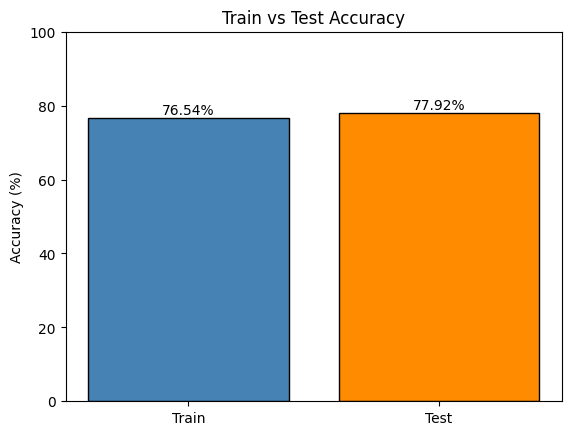

In [33]:
plt.bar(['Train', 'Test'], [train_acc*100, test_acc*100], color=['steelblue', 'darkorange'], edgecolor='black')
for i, v in enumerate([train_acc*100, test_acc*100]):
    plt.text(i, v + 1, f'{v:.2f}%', ha='center')
plt.ylim(0, 100)
plt.ylabel('Accuracy (%)')
plt.title('Train vs Test Accuracy')
plt.show()

- Δεν υπάρχει overfitting γιατί τα νούμερα είναι κοντά (το μοντέλο δεν αποστήθισε τα δεδομένα εκπαίδευσης, αλλά δουλεύει καλά και σε νέους ασθενείς).
- Το ότι το test είναι λίγο καλύτερο από το train οφείλεται στην τύχη του διαχωρισμού.
- Ταυτόχρονα, και οι δύο τιμές είναι μέτριες (~77%), γιατί η Λογιστική Παλινδρόμηση είναι απλό μοντέλο και δεν μπορεί να ξεχωρίσει τέλεια τους διαβητικούς από τους υγιείς.

## Ερώτημα 1.4 – Γλυκόζη και διαβήτης

### Ποσοστό διαβητικών ανά επίπεδο γλυκόζης

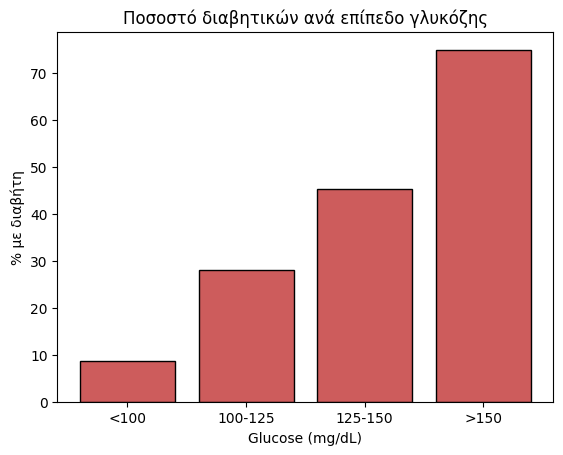

In [34]:
glu = df[df['Glucose'] > 0]
glu_groups = pd.cut(glu['Glucose'], bins=[0, 100, 125, 150, 200], labels=['<100', '100-125', '125-150', '>150'])
diabetes_rate = glu.groupby(glu_groups, observed=True)['Outcome'].mean() * 100

plt.bar(diabetes_rate.index, diabetes_rate.values, color='indianred', edgecolor='black')
plt.title('Ποσοστό διαβητικών ανά επίπεδο γλυκόζης')
plt.xlabel('Glucose (mg/dL)')
plt.ylabel('% με διαβήτη')
plt.show()

### Σημαντικότητα χαρακτηριστικών

In [35]:
scaler = StandardScaler()
scaler.fit(x_train)

x_train_sc = scaler.transform(x_train)
x_test_sc = scaler.transform(x_test)

model_sc = LogisticRegression(max_iter=5000, random_state=seed)
model_sc.fit(x_train_sc, y_train)

y_pred_sc = model_sc.predict(x_test_sc)
accuracy = accuracy_score(y_test, y_pred_sc)
accuracy_percentage = round(accuracy*100, 2)

print(f'The accuracy of the model is: {accuracy_percentage}')

The accuracy of the model is: 77.92


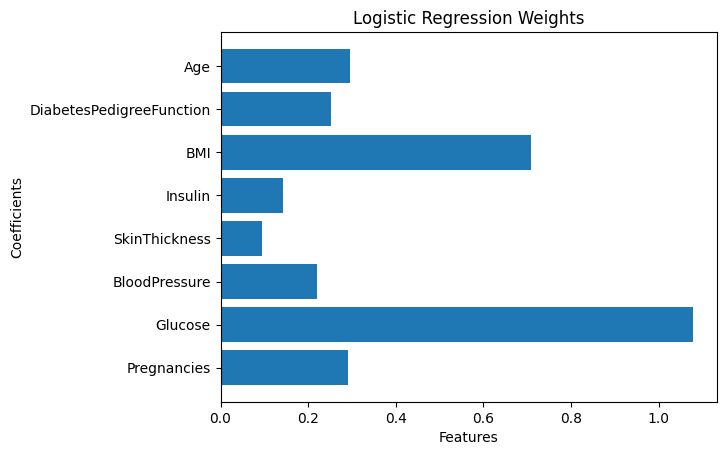

Glucose coefficient: 1.08


In [36]:
coeffs = model_sc.coef_[0]
importance_weights = np.abs(coeffs)
plt.barh(input_df.columns, importance_weights)
plt.title('Logistic Regression Weights')
plt.xlabel('Features')
plt.ylabel('Coefficients')
plt.show()

print(f'Glucose coefficient: {coeffs[1]:.2f}')

**Συμπέρασμα:** Όσο αυξάνεται η γλυκόζη, αυξάνεται και το ποσοστό των ασθενών με διαβήτη. Στους ασθενείς με γλυκόζη κάτω από 100 λιγότεροι από 10% έχουν διαβήτη, ενώ σε όσους έχουν πάνω από 150 το ποσοστό ξεπερνά το 70%.

Το ίδιο φαίνεται και από το μοντέλο: η Glucose έχει το μεγαλύτερο βάρος από όλα τα χαρακτηριστικά και είναι θετικό, δηλαδή όσο ανεβαίνει η γλυκόζη, ανεβαίνει και η πιθανότητα διαβήτη.

Άρα τα δεδομένα επιβεβαιώνουν την κλινική μελέτη.



## Ερώτημα 1.5 – Ακρίβεια ανά ηλικιακή ομάδα

0-25: 90 ασθενείς, accuracy 85.6%
25-50: 120 ασθενείς, accuracy 70.0%
>50: 21 ασθενείς, accuracy 90.5%


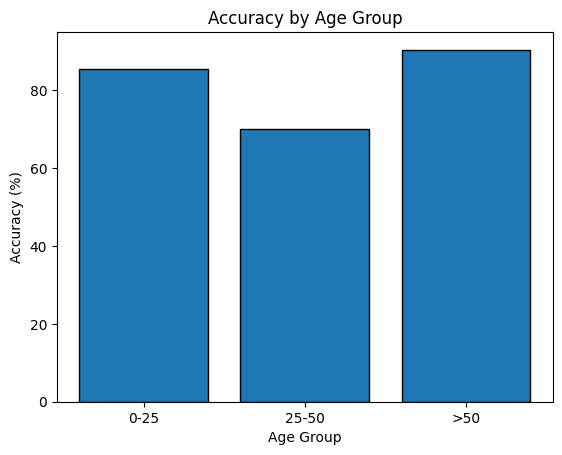

In [37]:
ages_test = x_test[:, 7]
age_groups = pd.cut(ages_test, bins=[0, 25, 50, 100], labels=['0-25', '25-50', '>50'])

accuracies = []
for group in ['0-25', '25-50', '>50']:
    mask = (age_groups == group)
    acc = accuracy_score(y_test[mask], y_test_pred[mask]) * 100
    accuracies.append(acc)
    print(f'{group}: {mask.sum()} ασθενείς, accuracy {acc:.1f}%')

plt.bar(['0-25', '25-50', '>50'], accuracies, edgecolor='black')
plt.title('Accuracy by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Accuracy (%)')
plt.grid(False)
plt.show()

**Συμπέρασμα:** Όχι, ο ταξινομητής δεν δουλεύει εξίσου καλά για όλες τις ηλικίες.

- **0–25:** καλή ακρίβεια. Οι περισσότεροι νέοι δεν έχουν διαβήτη, οπότε είναι πιο εύκολο για το μοντέλο να τους βρει σωστά.
- **25–50:** η χειρότερη ακρίβεια. Σε αυτή την ηλικία υπάρχουν πολλοί και υγιείς και διαβητικοί, οπότε είναι πιο δύσκολο να τους ξεχωρίσει.
- **>50:** η καλύτερη ακρίβεια, αλλά είναι μόνο 21 ασθενείς, οπότε το αποτέλεσμα δεν είναι πολύ αξιόπιστο.

## Ερώτημα 1.6 - False Positive ή False Negative;

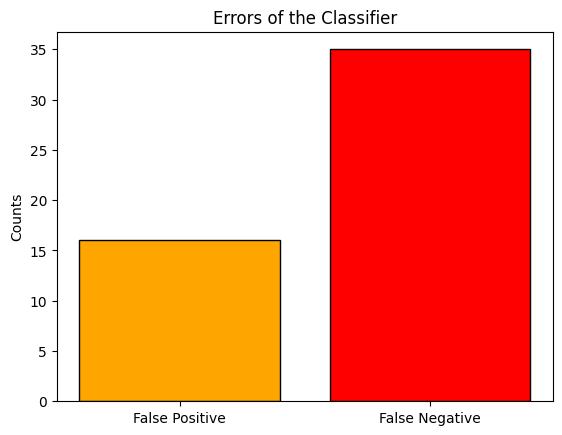

False Positive: 16 υγιείς ασθενείς χαρακτηρίστηκαν διαβητικοί
False Negative: 35 διαβητικοί ασθενείς χαρακτηρίστηκαν υγιείς


In [38]:
fp = ((y_test == 0) & (y_test_pred == 1)).sum()
fn = ((y_test == 1) & (y_test_pred == 0)).sum()

plt.bar(['False Positive', 'False Negative'], [fp, fn], color=['orange', 'red'], edgecolor='black')
plt.title('Errors of the Classifier')
plt.ylabel('Counts')
plt.grid(False)
plt.show()

print(f'False Positive: {fp} υγιείς ασθενείς χαρακτηρίστηκαν διαβητικοί')
print(f'False Negative: {fn} διαβητικοί ασθενείς χαρακτηρίστηκαν υγιείς')

**Χειρότερο είναι το False Negative**, δηλαδή να πει το μοντέλο ότι κάποιος δεν έχει διαβήτη ενώ έχει.

Αν ένας υγιής χαρακτηριστεί διαβητικός, θα κάνει άλλη μια εξέταση και θα φανεί ότι είναι καλά. Αν όμως ένας διαβητικός χαρακτηριστεί υγιής, δεν θα πάρει θεραπεία και η υγεία του θα χειροτερέψει.

Το μοντέλο μας χαρακτήρισε υγιείς 35 διαβητικούς ασθενείς, ενώ μόνο 16 υγιείς χαρακτηρίστηκαν διαβητικοί. Δηλαδή κάνει πιο συχνά το λάθος που είναι και το πιο επικίνδυνο.

# Μέρος 2 – Γραμμική Παλινδρόμηση

## Ερώτημα 2.1 - Numpy arrays και διαχωρισμός Train-Validation

In [39]:
df = pd.read_csv('diabetes.csv')

reg_features = ['Pregnancies', 'BloodPressure', 'BMI', 'Age']
x_reg = df[reg_features].to_numpy()
y_reg = df['Glucose'].to_numpy()

x_train_r, x_test_r, y_train_r, y_test_r = train_test_split(x_reg, y_reg, test_size=0.3, random_state=0)

print(f'x: {x_reg.shape}, y: {y_reg.shape}')
print(f'Δεδομένα εκπαίδευσης: {x_train_r.shape[0]}')
print(f'Δεδομένα επικύρωσης:  {x_test_r.shape[0]}')

x: (768, 4), y: (768,)
Δεδομένα εκπαίδευσης: 537
Δεδομένα επικύρωσης:  231


## Ερώτημα 2.2 - Πρόβλεψη γλυκόζης: MAE ή MSE;

In [40]:
reg = LinearRegression()
reg.fit(x_train_r, y_train_r)

y_pred_r = reg.predict(x_test_r)

mae = mean_absolute_error(y_test_r, y_pred_r)
mse = mean_squared_error(y_test_r, y_pred_r)

print(f'MAE: {mae:.2f}')
print(f'MSE: {mse:.2f}')

MAE: 23.60
MSE: 929.89


**Καταλληλότερη μετρική είναι το MAE.**

Το MAE είναι στις ίδιες μονάδες με τη γλυκόζη (mg/dL), οπότε καταλαβαίνουμε εύκολα ότι το μοντέλο κάνει λάθος κατά μέσο όρο περίπου 24 mg/dL. Το MSE είναι σε mg/dL στο τετράγωνο, που δεν έχει πρακτικό νόημα.

Επίσης, στο MSE τα μεγάλα λάθη μετράνε πολύ περισσότερο, γιατί υψώνονται στο τετράγωνο. Στα δεδομένα μας κάποια μεγάλα λάθη οφείλονται στις ελλιπείς τιμές (π.χ. γλυκόζη 0), οπότε το MSE δείχνει το μοντέλο χειρότερο απ' ό,τι είναι.


## Ερώτημα 2.3 - Η πιο σημαντική μεταβλητή

### Κανονικοποίηση (StandardScaler)

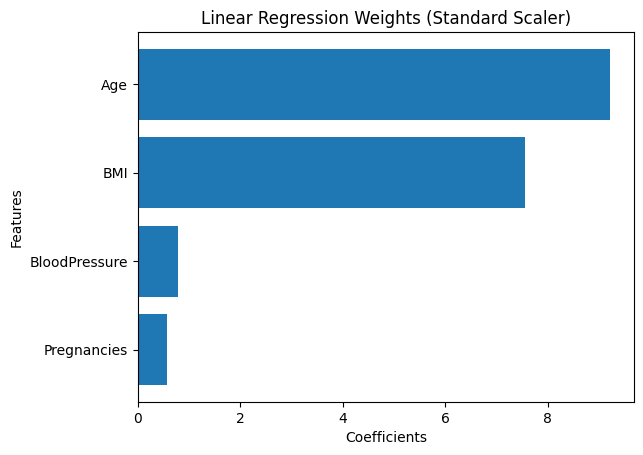

[-0.57  0.79  7.56  9.21]


In [41]:
scaler = StandardScaler()
scaler.fit(x_train_r)

x_train_rs = scaler.transform(x_train_r)
x_test_rs = scaler.transform(x_test_r)

reg_sc = LinearRegression()
reg_sc.fit(x_train_rs, y_train_r)

plt.barh(reg_features, np.abs(reg_sc.coef_))
plt.title('Linear Regression Weights (Standard Scaler)')
plt.xlabel('Coefficients')
plt.ylabel('Features')
plt.show()

print(reg_sc.coef_.round(2))

### Ομαλοποίηση (Lasso)

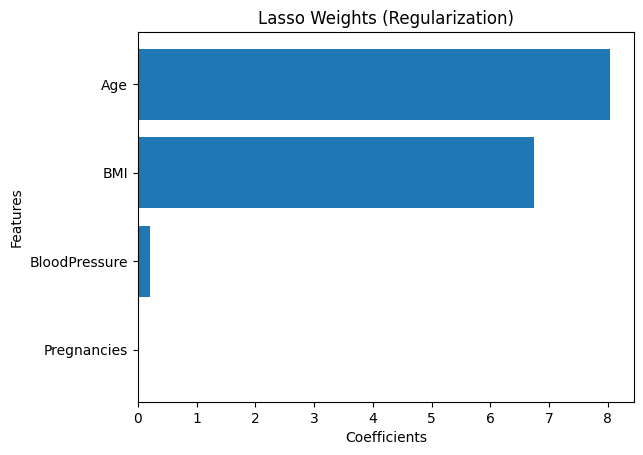

[0.   0.21 6.74 8.04]


In [42]:
lasso = Lasso(alpha=1.0)
lasso.fit(x_train_rs, y_train_r)

plt.barh(reg_features, np.abs(lasso.coef_))
plt.title('Lasso Weights (Regularization)')
plt.xlabel('Coefficients')
plt.ylabel('Features')
plt.show()

print(lasso.coef_.round(2))



**Κανονικοποίηση:** φέρνει όλες τις μεταβλητές στην ίδια κλίμακα, ώστε να μπορούμε να συγκρίνουμε τα βάρη τους. Η Age έχει το μεγαλύτερο βάρος (9.21).

**Ομαλοποίηση:** μηδενίζει τα βάρη των μεταβλητών που δεν είναι σημαντικές για την πρόβλεψη. Τα Pregnancies έγιναν 0 και η BloodPressure έμεινε πολύ μικρή, ενώ η Age κράτησε πάλι το μεγαλύτερο βάρος (8.04).

**Συμπέρασμα:** Και οι δύο μέθοδοι δείχνουν ότι η ηλικία είναι η πιο σημαντική μεταβλητή για την πρόβλεψη της γλυκόζης.